# PharmaML Toolkit — end-to-end walkthrough

This notebook exercises **every domain** of the `pharmaml` package on the
shipped demo files in `examples/data/`:

| Section | Domain | What you see |
|---|---|---|
| 1 | `pharmaml.data` | **bring your own file**: CSV → target auto-detection → task inference (multiclass / regression) |
| 2 | `pharmaml.ml` | dataset → split → cross-validated training → evaluation → save/load |
| 3 | `pharmaml.ml` | multiclass classification (3 classes) end-to-end |
| 4 | `pharmaml.ml` | model-comparison leaderboard |
| 5 | `pharmaml.pharma` | non-compartmental PK, renal function, dosage design |
| 6 | `pharmaml.docking` | Vina output parsing + ligand-efficiency scoring |
| 7 | `pharmaml.chem` | IC50 → pIC50 endpoint conversion |

**Setup** — install the package first:

```bash
pip install -e ".[dev]"
```

No external datasets are required — the demo tables ship in `examples/data/`
(regenerated deterministically via `scratch/build_example_data.py`), so the
notebook runs offline and is fully reproducible.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from pharmaml import __version__

# The shipped demo inventory: every demo table below is loaded from
# examples/data/ instead of fabricated inline.
DATA_DIR = Path("data")

print(f"pharmaml {__version__}")


pharmaml 1.2.115


## 1 · Bring your own data

`pharmaml.data.load_dataset` is the entry point for **your own files** (CSV/TSV/Excel):
it auto-detects the target column, infers whether the endpoint is classification
(**any number of classes**, string or integer labels) or regression, drops
non-numeric feature columns visibly, and reports class balance before training.

CLI equivalent:

```bash
pharmaml data inspect --data my_compounds.csv --target activity
pharmaml ml train   --data my_compounds.csv --task auto
```


In [2]:
from pharmaml.data import infer_task, load_dataset

# The shipped demo table: descriptors + string target + SMILES metadata
# column -- exactly the shape a user file arrives in.
demo_file = DATA_DIR / "walkthrough_compounds.csv"   # <- replace with your own path

ds = load_dataset(demo_file)               # target auto-detected -> 'activity'
print(ds.summary())
print("\nclasses:", ds.classes)
print("dropped non-numeric columns:", ds.dropped_columns)
print("task inference on a pIC50-like target:",
      infer_task(pd.Series(np.linspace(4, 9, 100))))


Excluding 1 non-numeric column(s) from features: ['SMILES']


source        : data/walkthrough_compounds.csv
shape         : 180 rows x 8 columns (6 features (numeric))
target        : activity
task          : classification
missing cells : 0
dup. rows     : 0
classes (3): 'active': 39, 'inactive': 88, 'weak': 53
dropped cols  : SMILES  [non-numeric]

classes: ['active', 'inactive', 'weak']
dropped non-numeric columns: ['SMILES']
task inference on a pIC50-like target: regression


## 2 · Machine learning (QSAR)

The shipped binary-activity table → stratified split → `random_forest` with 5-fold
cross-validated grid search → held-out evaluation → artifact round-trip.


In [3]:
frame = pd.read_csv(DATA_DIR / "walkthrough_classification.csv")
frame.head()


,descr_00,descr_01,descr_02,descr_03,descr_04,descr_05,descr_06,descr_07,Target
0,-0.933311,-0.350977,-0.094518,1.603977,-1.801661,-0.614773,1.098427,0.498729,0
1,0.948704,-2.464473,1.180392,0.624378,0.250446,-0.005397,2.691030,3.198781,0
2,-0.165862,0.590786,2.515123,0.521732,1.826580,0.641931,-1.195110,-1.395506,1
3,0.506339,0.024051,0.943334,1.056373,1.598499,0.297982,0.366438,-1.208509,0
4,-0.951452,-0.852139,1.647298,0.325212,-1.474478,0.250452,2.690493,3.655326,1


In [4]:
from pharmaml.ml import train_model, evaluate_model, make_train_test_split

X_train, X_test, y_train, y_test = make_train_test_split(
    frame.drop(columns=["Target"]), frame["Target"], test_size=0.2, random_state=42
)

result = train_model(
    "random_forest", "classification", X_train, y_train, cv=5, tune=True
)
print(f"{result.name}: CV ROC-AUC {result.cv_mean:.3f} ± {result.cv_std:.3f} "
      f"in {result.fit_seconds:.1f}s")
print("Best params:", result.best_params)

random_forest: CV ROC-AUC 0.924 ± 0.031 in 28.7s
Best params: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 100}


In [5]:
report = evaluate_model(result.model, X_test, y_test, "classification")
print(f"accuracy={report.accuracy:.3f}  balanced={report.balanced_accuracy:.3f}  "
      f"f1_macro={report.f1_macro:.3f}  roc_auc={report.roc_auc:.3f}")
print("Confusion matrix (rows=true, cols=pred):")
print(report.confusion)

accuracy=0.833  balanced=0.833  f1_macro=0.833  roc_auc=0.904
Confusion matrix (rows=true, cols=pred):
[[26  4]
 [ 6 24]]


In [6]:
from pathlib import Path

from pharmaml.ml import save_model, load_model

Path("artifacts").mkdir(exist_ok=True)
save_model(
    result.model, "artifacts/rf_demo.joblib", name="random_forest",
    task="classification",
    features=[c for c in frame.columns if c != "Target"],
    best_params=result.best_params,
    metrics={"accuracy": report.accuracy},
)
loaded_model, metadata = load_model("artifacts/rf_demo.joblib")
print("Reloaded:", metadata["name"], "| accuracy", round(metadata["metrics"]["accuracy"], 3))

Reloaded: random_forest | accuracy 0.833


## 3 · Multiclass classification (two or more classes)

A target with 3+ distinct values is handled natively: stratified splits keep every
class in both partitions, metrics are macro-averaged, the confusion matrix is k×k
and ROC-AUC switches to one-vs-rest.


In [7]:
multi = pd.read_csv(DATA_DIR / "walkthrough_multiclass.csv")

X_tr, X_te, y_tr, y_te = make_train_test_split(
    multi.drop(columns=["Target"]), multi["Target"], test_size=0.25
)
mc = train_model("logistic_regression", "classification", X_tr, y_tr, tune=False)
mc_report = evaluate_model(mc.model, X_te, y_te, "classification")

print(f"3-class accuracy={mc_report.accuracy:.3f}  f1_macro={mc_report.f1_macro:.3f}  "
      f"roc_auc(ovr)={mc_report.roc_auc:.3f}")
print("classes present in train and test folds:", sorted(y_tr.unique()), sorted(y_te.unique()))
print("k x k confusion matrix:\n", mc_report.confusion)


3-class accuracy=0.760  f1_macro=0.759  roc_auc(ovr)=0.892
classes present in train and test folds: [0, 1, 2] [0, 1, 2]
k x k confusion matrix:
 [[16  2  8]
 [ 0 22  3]
 [ 1  4 19]]


## 4 · Model leaderboard

`compare_models` cross-validates several registry models and returns a
`DataFrame` sorted by the primary metric (ROC-AUC, one-vs-one — falling back to
balanced accuracy when a member lacks `predict_proba`).


In [8]:
from pharmaml.ml import compare_models

leaderboard = compare_models(
    frame.drop(columns=["Target"]), frame["Target"],
    "classification", models=["logistic_regression", "knn", "random_forest"], cv=5,
)
leaderboard

,model,roc_auc_ovo_mean,roc_auc_ovo_std,fit_time_s,folds
0,random_forest,0.910529,0.020990,0.105524,5
1,knn,0.903418,0.023908,0.003509,5
2,logistic_regression,0.877295,0.028300,0.005154,5


## 5 · Pharmaceutical calculations

Non-compartmental analysis of a plasma profile, then renal function
(Cockcroft–Gault), BSA scaling (Mosteller) and regimen design.


In [9]:
from pharmaml.pharma.pk import nca_summary

times = [0.0, 0.5, 1.0, 2.0, 4.0, 8.0, 12.0, 24.0]
conc = [0.0, 9.8, 12.4, 10.2, 6.1, 2.3, 0.8, 0.05]

summary = nca_summary(times, conc)
pd.Series(summary.as_dict(), name="value").round(3)

AUC                 63.700
AUMC               273.150
MRT                  4.288
Cmax                12.400
Tmax                 1.000
t_half_terminal      3.000
Name: value, dtype: float64

In [10]:
from pharmaml.pharma import (
    bsa_mosteller, creatinine_clearance, dose_by_bsa,
    half_life, loading_dose, maintenance_dose,
)

crcl = creatinine_clearance(age_years=68, weight_kg=70, serum_cr_mg_dl=1.1, sex="male")
bsa = bsa_mosteller(height_cm=175, weight_kg=70)

print(f"CrCl = {crcl:.1f} mL/min (male)   BSA = {bsa:.2f} m²")
print(f"BSA-scaled dose  = {dose_by_bsa(dose_per_m2=250, height_cm=175, weight_kg=70):.0f} mg")
print(f"Loading dose     = {loading_dose(vd=45.0, target_concentration=12.0):.0f} mg")
print(f"Maintenance dose = {maintenance_dose(clearance_=3.2, target_css=6.0, tau=8.0):.1f} mg q8h")
print(f"t½ at ke = 0.115 h⁻¹: {half_life(0.115):.1f} h")

CrCl = 63.6 mL/min (male)   BSA = 1.84 m²
BSA-scaled dose  = 461 mg
Loading dose     = 540 mg
Maintenance dose = 153.6 mg q8h
t½ at ke = 0.115 h⁻¹: 6.0 h


## 6 · Molecular docking

Parsing a Vina output table and adding **ligand efficiency**
(`LE = |ΔG| / N_heavy`) — the size-normalised affinity metric.


In [11]:
from pharmaml.docking import ligand_efficiency, parse_vina_output

VINA_LOG = """\
Estimated Free Energy of Binding   = -10.3 kcal/mol
mode | affinity | dist from best mode
     |          | rmsd l.b. | rmsd u.b.
-----+----------+-----------+----------
   1      -10.3          0          0
   2       -9.6      1.842      2.301
   3       -9.4      2.105      2.777
   4       -8.9      2.733      3.418
-----+----------+-----------+----------
"""

poses = parse_vina_output(VINA_LOG)
table = pd.DataFrame(
    [(p.mode, p.affinity, p.rmsd_lb, p.rmsd_ub) for p in poses],
    columns=["mode", "affinity", "rmsd_lb", "rmsd_ub"],
)
table["ligand_efficiency"] = [ligand_efficiency(p.affinity, 32) for p in poses]
table.round(3)

,mode,affinity,rmsd_lb,rmsd_ub,ligand_efficiency
0,1,-10.3,0.000,0.000,0.322
1,2,-9.6,1.842,2.301,0.300
2,3,-9.4,2.105,2.777,0.294
3,4,-8.9,2.733,3.418,0.278


## 7 · Endpoint conversion

pIC50 is the log-transformed IC50 that QSAR models actually regress on.


In [12]:
from pharmaml.chem import ic50_to_pic50

for ic50_nM in (10.0, 100.0, 1000.0, 2500.0):
    print(f"IC50 = {ic50_nM:7.1f} nM  ->  pIC50 = {ic50_to_pic50(ic50_nM, 'nM'):.2f}")

IC50 =    10.0 nM  ->  pIC50 = 8.00
IC50 =   100.0 nM  ->  pIC50 = 7.00
IC50 =  1000.0 nM  ->  pIC50 = 6.00
IC50 =  2500.0 nM  ->  pIC50 = 5.60


## 8 · Molecule generation — invent, don't just analyse

`pharmaml.generative` closes the loop: instead of only analysing molecules
you already have, it *optimises* molecules towards an objective.
`GeneticOptimizer` is a deterministic SMILES genetic algorithm with two
structural modes beyond the classic character mutation:

* `mutation="scaffold"` — keep the parent's Murcko framework verbatim and
  resample its decorations (lead optimisation);
* `crossover="scaffold_hop"` — BREED-style recombination: cut two parents
  at a pair of homologous single bonds and recombine them — fragments
  swapped cross-wise, two rings merged into one, a two-ended linker
  — a single atom or a short acyclic path — transplanted into a cut
  ring bond, a whole ring spliced across the cut into a fused
  bicyclic, or a whole ring spliced into a cut acyclic bond as the
  spacer, or a two-point segment swap exchanging one parent's bounded
  acyclic middle — a single atom or a short path — for the other's
  homologous middle (the bioisostere exchange: an ester O for an
  amide N) — so the offspring's framework
  differs from *both* parents: the scaffold hop;
* `mutation="topology"` — ring-size mutation, the single-parent moves:
  one atom removed from a saturated ring (contraction — piperidine →
  pyrrolidine) or one methylene inserted into a saturated single ring
  bond (expansion — piperidine → azepane), the ring-size axis of
  scaffold morphing.

The seed molecules load from the shipped `data/seed_molecules.csv` (a
dozen named drugs) — swap in your own file for a seeded run over your
chemistry.

One honest observation to set expectations: the character-level GA
invents *freely* — its best de novo molecule below even carries an
aromatic phosphorus (`[pH]`): chemically valid, decidedly exotic, and
exactly why the structural modes exist — they only recombine chemistry
that already works.


In [13]:
from pharmaml.generative import (
    GeneticOptimizer, LogPBandObjective, MultiObjective, QedObjective,
)

objective = MultiObjective(
    [QedObjective(), LogPBandObjective(1.0, 3.0)], weights=[0.7, 0.3])

de_novo = GeneticOptimizer(
    objective, population_size=32, generations=5, seed=42).optimize()
print(f"de novo: {len(de_novo)} unique, best score {de_novo.best_score:.3f}")
print(f"best:    {de_novo.best}")

seed_table = pd.read_csv(DATA_DIR / "seed_molecules.csv")
seeds = seed_table["smiles"].tolist()
seeded = GeneticOptimizer(
    objective, population_size=32, generations=8, seed=42,
    crossover="scaffold_hop").optimize(seed_smiles=seeds)
print(f"seeded + scaffold-hop: {len(seeded)} unique, best {seeded.best_score:.3f}")
seeded.to_dataframe().head(5)[["smiles", "score", "rank"]]


de novo: 137 unique, best score 0.928
best:    COc1cnc[pH]c(C)cc(Cc2cnc(N)nc2N)c1


[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond


[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond


[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond


[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond


[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:26] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27]

... (3 outputs left out)

[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:27] Incomplete atom labelling, cannot make bond
[10:02:28] Incomplete atom labelling, cannot make bond
[10:02:28] Incomplete atom labelling, cannot make bond
[10:02:28] Incomplete atom labelling, cannot make bond
[10:02:28] Incomplete atom labelling, cannot make bond
[10:02:28] Incomplete atom labelling, cannot make bond
[10:02:28]

[10:02:28] Incomplete atom labelling, cannot make bond
[10:02:28] Incomplete atom labelling, cannot make bond
[10:02:28] Incomplete atom labelling, cannot make bond
[10:02:28] Incomplete atom labelling, cannot make bond


seeded + scaffold-hop: 206 unique, best 0.851


,smiles,score,rank
0,CCOc1cnc(NNc2ccc(OC)cc2)cc#1,0.850575,1
1,CCN(CC)CC(=O)Nc1c(C)cccc1C,0.847277,2
2,CC(C)NCC(O)COc1cccc2ccccc12,0.840167,3
3,CCOc1ccc(NC(C)=O)cc1,0.833081,4
4,CCOc1ccc(NC(=O)OF)cc1,0.830993,5


In [14]:
import random

from pharmaml.generative import scaffold_hop_crossover

# the standalone operator: one homologous cut per parent, one hybrid child
draw = random.Random(0)
hybrid = scaffold_hop_crossover(seeds[0], seeds[9], draw)  # aspirin x naproxen
print(f"parent A:  {seeds[0]}   (aspirin)")
print(f"parent B:  {seeds[9]}   (naproxen)")
print(f"hybrid:    {hybrid}")


parent A:  CC(=O)Oc1ccccc1C(=O)O   (aspirin)
parent B:  COc1ccc2cc(C(C)C(=O)O)ccc2c1   (naproxen)
hybrid:    COc1ccc2cc(C(C)C(=O)C(=O)c3ccccc3OC(C)=O)ccc2c1


## 9 · Data utilities — the every-day lab chores

The original toolkit's most-run scripts were plain chores: converting
CSV↔SDF↔`.smi`, merging per-ligand tables, splitting a huge file,
listing stems, filtering approved drugs, scanning Tanimoto similarity
and walking docking campaign folders.  The library productionised each
one — this section tours them on the shipped demo data (the same
surface the desktop playground's Utilities tab drives with a mouse).

In [15]:
from pharmaml.chem.converters import smi_to_csv, sdf_to_table, table_to_sdf

Path("artifacts").mkdir(exist_ok=True)

library = pd.read_csv(DATA_DIR / "ligand_library.csv")

# CSV table -> 3D SDF (ETKDG embed + UFF; every extra column an SD tag).
# Rows whose SMILES fail to parse are counted, never silently dropped.
report = table_to_sdf(library, "artifacts/library.sdf",
                      smiles_col="SMILES", name_col="name")
print(f"wrote {report.molecules} molecules "
      f"({report.embedded_3d} with 3D coordinates, "
      f"{report.failures} unparseable kept honest) -> {report.output_sdf}")

# ...and back again: SDF -> table (titles, canonical SMILES, typed tags)
round_trip = sdf_to_table("artifacts/library.sdf")
print(round_trip[["name", "SMILES"]].head(2).to_string(index=False))

# .smi two-column list -> CSV (the 'Convert SMI to CSV.py' chore)
Path("artifacts/list.smi").write_text("CCO ethanol\nCC(C)CO isopropanol\n")
smi_csv = smi_to_csv("artifacts/list.smi", "artifacts/list.csv")
print(pd.read_csv(smi_csv).to_string(index=False))

Invalid SMILES at row 9: 'not_a_smiles'


Invalid SMILES at row 10: nan


wrote 8 molecules (8 with 3D coordinates, 2 unparseable kept honest) -> artifacts/library.sdf
     name                          SMILES
  aspirin           CC(=O)Oc1ccccc1C(=O)O
ibuprofen CC(C)Cc1ccc([C@@H](C)C(=O)O)cc1
 SMILES          ID
    CCO     ethanol
CC(C)CO isopropanol


In [16]:
from pharmaml.chem.converters import split_table_into_chunks
from pharmaml.chem.tables import annotate_with_smiles, compare_tables, merge_tables
from pharmaml.ml.preprocessing import clean_numeric_frame

# row-wise merge of several tables, named columns first (CSV_merger.py)
merged = merge_tables(
    [pd.read_csv(DATA_DIR / "ligand_library.csv"),
     pd.read_csv(DATA_DIR / "seed_molecules.csv")],
    first_columns=["name", "smiles"],
)
print(f"merged {len(merged)} rows; first columns: {list(merged.columns)[:2]}")

# compare one ligand-name column across two tables (notcommon.py +
# common_between_two_excel.py -> one set reconciliation)
comparison = compare_tables(
    pd.read_csv(DATA_DIR / "ligand_library.csv"),
    pd.read_csv(DATA_DIR / "seed_molecules.csv"),
    column="name",
)
print("common:", len(comparison.common),
      "| only in A:", len(comparison.only_in_a),
      "| only in B:", len(comparison.only_in_b))

# annotate bare ligand names with SMILES from a lookup (smilesgetter.py)
annotated = annotate_with_smiles(
    pd.DataFrame({"ligand": ["aspirin", "naproxen", "unknown"]}),
    pd.read_csv(DATA_DIR / "ligand_library.csv"),
    name_columns=["ligand"],
    reference_name_column="name",
)
print(annotated.to_string(index=False))

# stream a large CSV into fixed-size parts (Split CSV file.py)
parts = split_table_into_chunks(
    DATA_DIR / "qsar_regression.csv", "artifacts/parts", chunk_rows=40,
)
print(f"split into {len(parts)} parts: "
      f"{[p.name for p in parts[:2]]} ...")

# drop non-numeric columns but keep the SMILES (Non-numerical remover.py)
cleaned = clean_numeric_frame(
    pd.read_csv(DATA_DIR / "walkthrough_classification.csv"),
    keep_cols=["SMILES"],
)
print("kept:", list(cleaned.columns)[:4], "...")

merged 22 rows; first columns: ['name', 'smiles']
common: 5 | only in A: 5 | only in B: 7
  ligand                ligand_SMILES
 aspirin        CC(=O)Oc1ccccc1C(=O)O
naproxen COc1ccc2cc(ccc2c1)C(C)C(=O)O
 unknown                             


split into 7 parts: ['qsar_regression_part001.csv', 'qsar_regression_part002.csv'] ...
kept: ['descr_00', 'descr_01', 'descr_02', 'descr_03'] ...


In [17]:
from pharmaml.chem.tables import merge_table_folder
from pharmaml.docking.campaign import list_file_names
from pharmaml.pharma.approvals import filter_approved_drugs

# list the stems of every csv in a folder (Nameextracter.py)
names = list_file_names(DATA_DIR, extension=".csv")
print(f"{len(names)} csv files in data/ | first 3: {names[:3]}")

# filter approved drugs from an approval table (approved.py)
approvals = pd.DataFrame({
    "drug": ["aspirin", "caffeine", "ibuprofen"],
    "regulatory approval": ["approved", "withdrawn", "approved"],
})
print("approved:", filter_approved_drugs(approvals))

# merge every part back into one table (filemerger.py) — split's twin
merged_back = merge_table_folder("artifacts/parts")
print(f"merged back {len(merged_back)} rows from the {len(parts)} parts")

13 csv files in data/ | first 3: ['cellline_expression', 'cellline_screen', 'library_with_descriptors']
approved: ['aspirin', 'ibuprofen']
merged back 260 rows from the 7 parts


In [18]:
from pharmaml.chem.similarity import similarity_scan, top_matches

references = ["CC(=O)Oc1ccccc1C(=O)O", "CC(C)Cc1ccc(cc1)C(C)C(=O)O"]
library_smiles = pd.read_csv(DATA_DIR / "ligand_library.csv")["SMILES"].dropna().tolist()

# threshold scan: reference x library, long-format pairs (Tanimoto calculator.py)
pairs = similarity_scan(references, library_smiles, threshold=0.4)
print(pairs.sort_values("similarity", ascending=False).head(4).to_string(index=False))

# top-k nearest neighbours of one query (Tanimoto-edited.py)
nearest = top_matches("CC(=O)Oc1ccccc1C(=O)O", library_smiles, k=3)
print(nearest.to_string(index=False))

Dropping 1 invalid SMILES: ["index 8: 'not_a_smiles'"]
[10:02:28] SMILES Parse Error: syntax error while parsing: not_a_smiles
[10:02:28] SMILES Parse Error: check for mistakes around position 3:
[10:02:28] not_a_smiles
[10:02:28] ~~^
[10:02:28] SMILES Parse Error: Failed parsing SMILES 'not_a_smiles' for input: 'not_a_smiles'


Dropping 1 invalid SMILES: ["index 8: 'not_a_smiles'"]


                 reference                       target  reference_index  target_index  similarity
     CC(=O)Oc1ccccc1C(=O)O        CC(=O)Oc1ccccc1C(=O)O                0             0    1.000000
CC(C)Cc1ccc(cc1)C(C)C(=O)O   CC(C)Cc1ccc(cc1)C(C)C(=O)O                1             1    1.000000
CC(C)Cc1ccc(cc1)C(C)C(=O)O COc1ccc2cc(ccc2c1)C(C)C(=O)O                1             4    0.505618
            reference                target  reference_index  target_index  similarity
CC(=O)Oc1ccccc1C(=O)O CC(=O)Oc1ccccc1C(=O)O                0             0    1.000000
CC(=O)Oc1ccccc1C(=O)O      COc1cc(C=O)ccc1O                0             7    0.312785
CC(=O)Oc1ccccc1C(=O)O   CCOC(=O)c1ccc(N)cc1                0             5    0.264574


[10:02:28] SMILES Parse Error: syntax error while parsing: not_a_smiles
[10:02:28] SMILES Parse Error: check for mistakes around position 3:
[10:02:28] not_a_smiles
[10:02:28] ~~^
[10:02:28] SMILES Parse Error: Failed parsing SMILES 'not_a_smiles' for input: 'not_a_smiles'


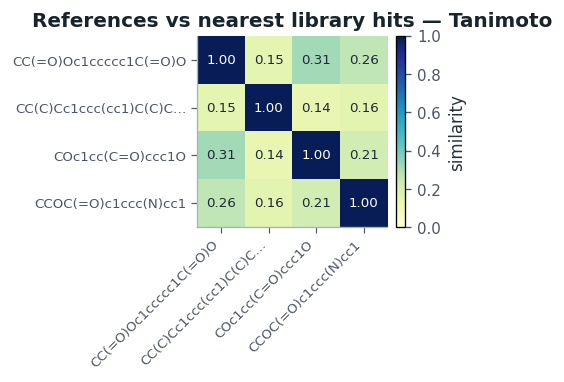

In [19]:
from pharmaml.chem import compute_fingerprints, tanimoto_matrix
from pharmaml.viz import plot_similarity_heatmap

# the same scan as a picture: the two reference drugs plus aspirin's
# three nearest library hits, one Tanimoto heat-map — the GUI twin of
# Tanimoto-edited.py's matrix view.  The tables above answer "which
# pairs pass the threshold"; the heat-map shows the BLOCKS: near-
# duplicates glow along the diagonal, distinct scaffolds stay dark.
panel = list(dict.fromkeys(references + nearest["target"].tolist()))
bits, _valid = compute_fingerprints(panel, kind="rdkit", n_bits=2048)
heat = tanimoto_matrix(bits, bits)
labels = [s if len(s) <= 22 else s[:21] + "…" for s in panel]

fig_heat = plot_similarity_heatmap(
    heat,
    labels=labels,
    title="References vs nearest library hits — Tanimoto",
)


### Docking campaign chores

The campaign side of the same coin: read a GPF back as typed
parameters, batch-write the `r.gpf`/`r.dpf` pair into every ligand
folder of a campaign tree (custom receptor atom types included — the
Ni-carrying `gpferreceptorni.py` case), and walk a results folder for
per-log best affinities.

In [20]:
from pharmaml.docking.campaign import write_config_batch
from pharmaml.docking.preparation import read_gpf

# read one GPF back as typed parameters (gpfreader.py)
Path("artifacts/r.gpf").write_text(
    "ligand_types C HD OA\nreceptor r.pdbqt\nreceptor_types A C HD N OA\n"
    "npts 40 40 40\nspacing 0.375\ngridcenter 0 0 0\n"
    "smooth 0.5\ndielectric -0.1465\n"
)
params = read_gpf("artifacts/r.gpf")
print("ligand types:", params["ligand_types"],
      "| npts:", params["npts"], "| spacing:", params["spacing"])

# batch-write r.gpf + r.dpf per campaign folder (gpfer.py / dpfer.py /
# gpferreceptorni.py — the Ni receptor types are the point here)
LIGAND_PDBQT = (
    "REMARK  Name = demo\nROOT\n"
    "ATOM      1  C   LIG A   1       0.000   0.000   0.000  1.00  0.00     C\n"
    "ATOM      2  O   LIG A   1       2.000   0.000   0.000  1.00  0.00     OA\n"
    "ENDROOT\nTORSDOF 1\n"
)
campaign = Path("artifacts/campaign")
for name in ("01_demo", "02_empty"):
    (campaign / name).mkdir(parents=True, exist_ok=True)
(campaign / "01_demo" / "l.pdbqt").write_text(LIGAND_PDBQT)
batch = write_config_batch(campaign, receptor_types="A C HD N Ni OA SA")
print(batch[["folder", "centre", "status"]].to_string(index=False))

ligand types: ['C', 'HD', 'OA'] | npts: (40, 40, 40) | spacing: 0.375
  folder            centre          status
 01_demo 1.000 0.000 0.000              ok
02_empty                   no ligand PDBQT


In [21]:
from pharmaml.docking.parsing import scan_vina_directory
from pharmaml.docking.workflow import run_vina_batch
from pharmaml.exceptions import DockingError

# a folder walk over Vina logs (vina_reader.py): best affinity per log,
# strongest binder first
vina_root = Path("artifacts/vina_results")
vina_root.mkdir(exist_ok=True)
for name, best in (("lig01", "-7.1"), ("lig02", "-8.4")):
    (vina_root / f"{name}.log").write_text(
        f"Estimated Free Energy of Binding   = {best} (kcal/mol)\n"
        f"REMARK VINA RESULT:    {best:<10} 0.000      0.000\n"
    )
scan = scan_vina_directory(vina_root)
print(scan.to_string(index=False))

# batch-docking every ligand with one config (vinar_multiple.py) —
# gates the engine BEFORE queue time; no vina binary here, so the
# actionable error fires instead of a cryptic crash:
Path("artifacts/vina.conf").write_text(
    "receptor = r.pdbqt\ncenter_x = 0\ncenter_y = 0\ncenter_z = 0\n"
    "size_x = 20\nsize_y = 20\nsize_z = 20\n")
Path("artifacts/r.pdbqt").write_text("ATOM receptor\n")
try:
    run_vina_batch("artifacts/vina.conf", "artifacts/campaign",
                   "artifacts/vina_results")
except DockingError as exc:
    print(f"[run_vina_batch] {exc}")

ligand       log  best_affinity  n_poses
 lig02 lig02.log           -8.4        1
 lig01 lig01.log           -7.1        1
[run_vina_batch] executable 'vina' not found on PATH -- install AutoDock Tools (autogrid4/autodock4) or AutoDock Vina first
